In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
RAW, PROC, FIG = Path("../data/raw"), Path("../data/processed"), Path("../reports/figures")
PROC.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)

In [3]:
gen1 = pd.read_csv(RAW/"Plant_1_Generation_Data.csv")
gen2 = pd.read_csv(RAW/"Plant_2_Generation_Data.csv")
w1   = pd.read_csv(RAW/"Plant_1_Weather_Sensor_Data.csv")
w2   = pd.read_csv(RAW/"Plant_2_Weather_Sensor_Data.csv")

gen1["DATE_TIME"] = pd.to_datetime(gen1["DATE_TIME"], format="%d-%m-%Y %H:%M")
for df in (gen2, w1, w2):
    df["DATE_TIME"] = pd.to_datetime(df["DATE_TIME"])

In [4]:
for name, df in [("Gen P1", gen1), ("Gen P2", gen2), ("Weather P1", w1), ("Weather P2", w2)]:
    print(f"--- {name} ---  shape={df.shape}")
    print("nulls:", df.isnull().sum().sum(), "| duplicates:", df.duplicated().sum())
    print("range:", df.DATE_TIME.min(), "->", df.DATE_TIME.max())

# Missing 15-minute intervals
for name, w in [("Plant 1", w1), ("Plant 2", w2)]:
    full = pd.date_range(w.DATE_TIME.min().normalize(), w.DATE_TIME.max().normalize() + pd.Timedelta("23h45min"), freq="15min")
    print(name, "missing weather intervals:", len(full.difference(w.DATE_TIME)))

print(gen1.groupby("SOURCE_KEY").size().describe())   # readings per inverter
gen1.describe().T

--- Gen P1 ---  shape=(68778, 7)
nulls: 0 | duplicates: 0
range: 2020-05-15 00:00:00 -> 2020-06-17 23:45:00
--- Gen P2 ---  shape=(67698, 7)
nulls: 0 | duplicates: 0
range: 2020-05-15 00:00:00 -> 2020-06-17 23:45:00
--- Weather P1 ---  shape=(3182, 6)
nulls: 0 | duplicates: 0
range: 2020-05-15 00:00:00 -> 2020-06-17 23:45:00
--- Weather P2 ---  shape=(3259, 6)
nulls: 0 | duplicates: 0
range: 2020-05-15 00:00:00 -> 2020-06-17 23:45:00
Plant 1 missing weather intervals: 82
Plant 2 missing weather intervals: 5
count      22.000000
mean     3126.272727
std        10.998623
min      3104.000000
25%      3120.000000
50%      3124.500000
75%      3129.000000
max      3155.000000
dtype: float64


,count,mean,min,25%,50%,75%,max,std
DATE_TIME,68778,2020-06-01 08:02:49.458257,2020-05-15 00:00:00,2020-05-24 00:45:00,2020-06-01 14:30:00,2020-06-09 20:00:00,2020-06-17 23:45:00,NaN
PLANT_ID,68778.0,4135001.0,4135001.0,4135001.0,4135001.0,4135001.0,4135001.0,0.0
DC_POWER,68778.0,3147.426211,0.0,0.0,429.0,6366.964286,14471.125,4036.457169
AC_POWER,68778.0,307.802752,0.0,0.0,41.49375,623.61875,1410.95,394.396439
DAILY_YIELD,68778.0,3295.968737,0.0,0.0,2658.714286,6274.0,9163.0,3145.178309
TOTAL_YIELD,68778.0,6978711.760671,6183645.0,6512002.53575,7146685.0,7268705.90625,7846821.0,416271.982856


In [5]:
cols = ["DATE_TIME", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE", "IRRADIATION"]
m1 = gen1.merge(w1[cols], on="DATE_TIME", how="inner"); m1["PLANT"] = 1
m2 = gen2.merge(w2[cols], on="DATE_TIME", how="inner"); m2["PLANT"] = 2
df = pd.concat([m1, m2], ignore_index=True)
df["HOUR"] = df.DATE_TIME.dt.hour
df["DATE"] = df.DATE_TIME.dt.date
print(df.shape)
df.to_csv(PROC/"merged_raw.csv", index=False)

(136472, 13)


PLANT
1    0.098
2    0.978
dtype: float64


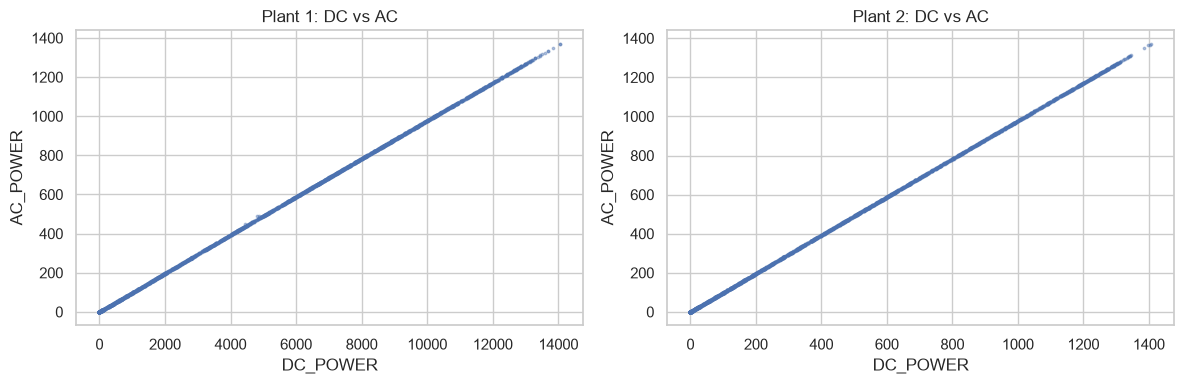

In [6]:
day = df[df.DC_POWER > 0]
print((day.groupby("PLANT").AC_POWER.sum() / day.groupby("PLANT").DC_POWER.sum()).round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharex=False)
for p, a in zip([1, 2], ax):
    s = df[df.PLANT == p].sample(5000, random_state=1)
    a.scatter(s.DC_POWER, s.AC_POWER, s=3, alpha=.4); a.set_title(f"Plant {p}: DC vs AC")
    a.set_xlabel("DC_POWER"); a.set_ylabel("AC_POWER")
plt.tight_layout(); plt.savefig(FIG/"dc_vs_ac.png", dpi=150); plt.show()

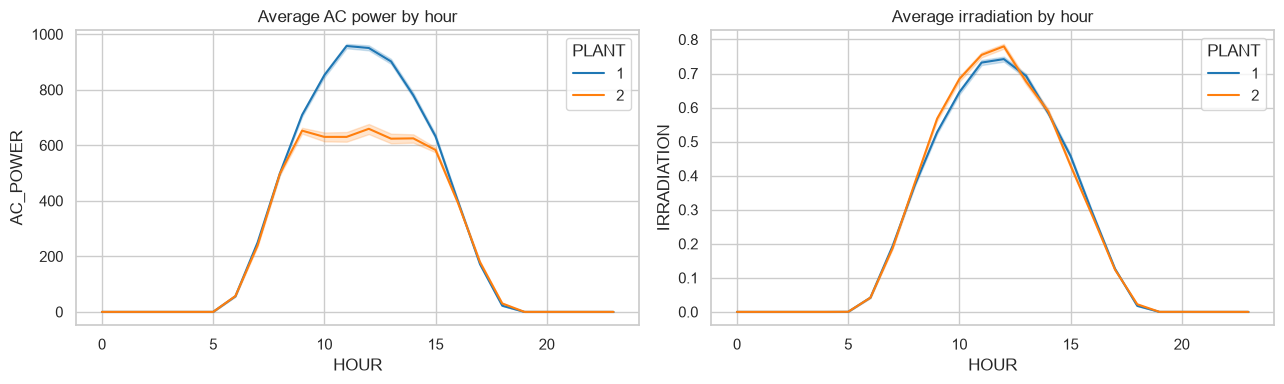

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.lineplot(data=df, x="HOUR", y="AC_POWER", hue="PLANT", palette="tab10", ax=ax[0])
ax[0].set_title("Average AC power by hour")
sns.lineplot(data=df, x="HOUR", y="IRRADIATION", hue="PLANT", palette="tab10", ax=ax[1])
ax[1].set_title("Average irradiation by hour")
plt.tight_layout(); plt.savefig(FIG/"hourly_profile.png", dpi=150); plt.show()

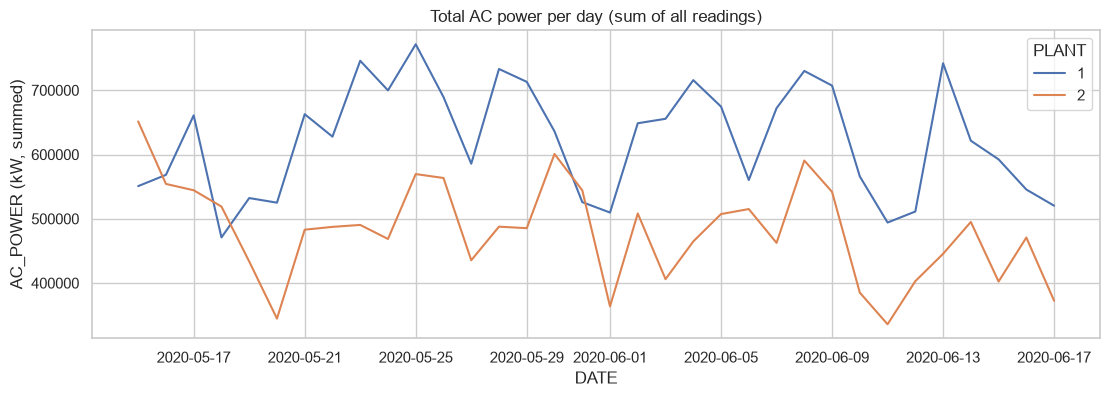

In [8]:
daily = df.groupby(["DATE", "PLANT"]).AC_POWER.sum().unstack()
daily.plot(figsize=(13, 4), title="Total AC power per day (sum of all readings)")
plt.ylabel("AC_POWER (kW, summed)"); plt.savefig(FIG/"daily_total.png", dpi=150); plt.show()

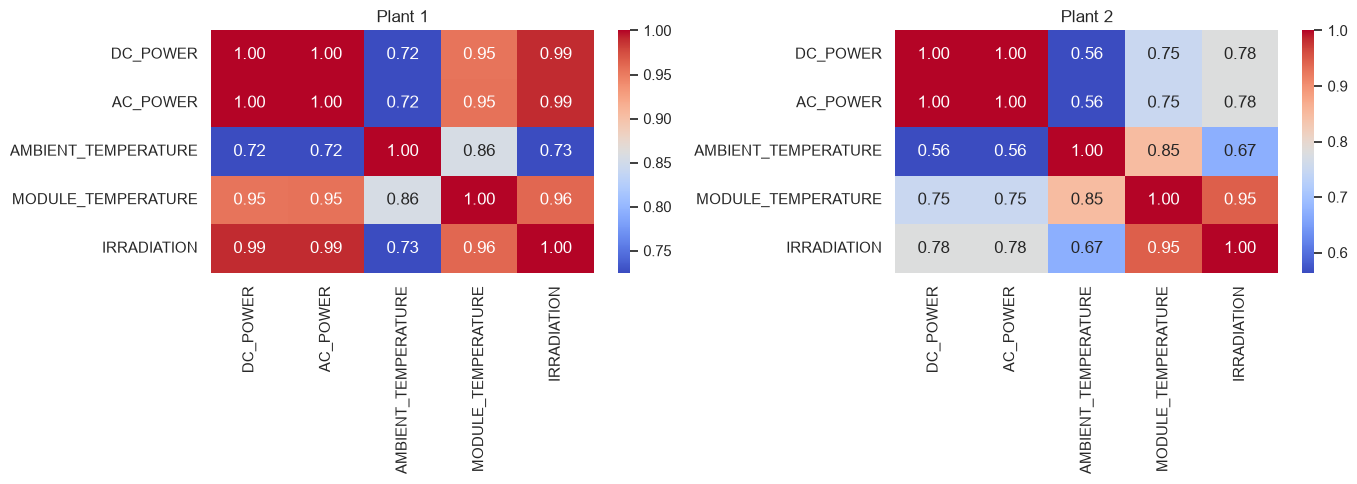

C:\Users\Hridhya\AppData\Local\Programs\Python\Python314\Lib\site-packages\seaborn\regression.py:598: UserWarning: sharey is deprecated from the `lmplot` function signature. Please update your code to pass it using `facet_kws`.
  warnings.warn(msg, UserWarning)


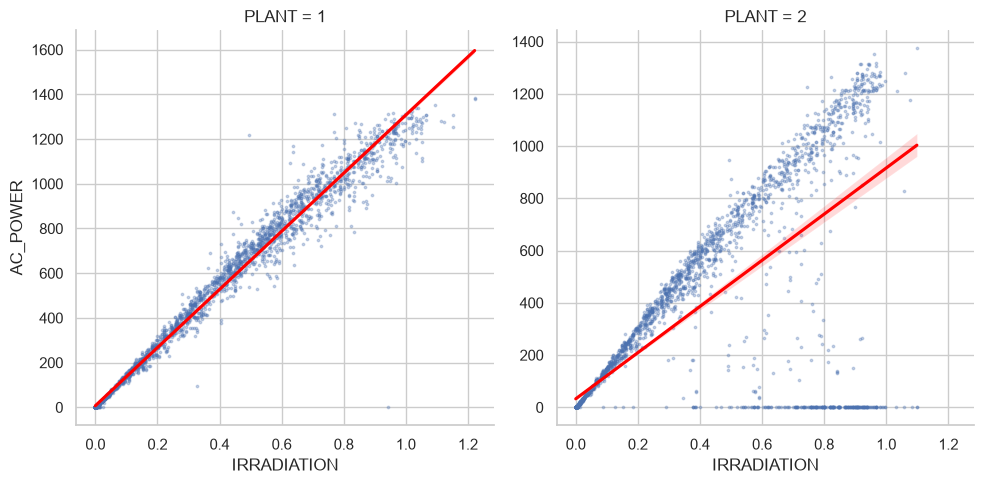

In [9]:
feat = ["DC_POWER", "AC_POWER", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE", "IRRADIATION"]
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for p, a in zip([1, 2], ax):
    sns.heatmap(df[df.PLANT == p][feat].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=a)
    a.set_title(f"Plant {p}")
plt.tight_layout(); plt.savefig(FIG/"correlation.png", dpi=150); plt.show()

sns.lmplot(data=df.sample(8000, random_state=1), x="IRRADIATION", y="AC_POWER", col="PLANT",
           scatter_kws={"s": 3, "alpha": .3}, line_kws={"color": "red"}, sharey=False)
plt.savefig(FIG/"irradiation_vs_power.png", dpi=150); plt.show()

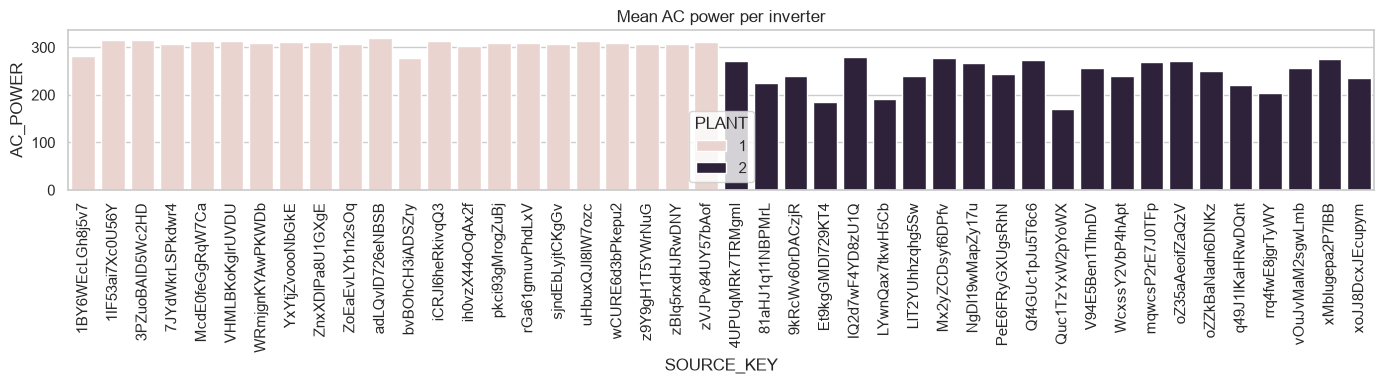

Zero-output rows despite sunlight:
 PLANT
1      62
2    3723
dtype: int64
SOURCE_KEY
LYwnQax7tkwH5Cb    316
Et9kgGMDl729KT4    302
Quc1TzYxW2pYoWX    279
rrq4fwE8jgrTyWY    267
81aHJ1q11NBPMrL    241
q49J1IKaHRwDQnt    239
xoJJ8DcxJEcupym    204
9kRcWv60rDACzjR    203
LlT2YUhhzqhg5Sw    196
WcxssY2VbP4hApt    195
dtype: int64


In [10]:
inv = df.groupby(["PLANT", "SOURCE_KEY"]).AC_POWER.mean().reset_index()
plt.figure(figsize=(14, 4))
sns.barplot(data=inv, x="SOURCE_KEY", y="AC_POWER", hue="PLANT"); plt.xticks(rotation=90)
plt.title("Mean AC power per inverter"); plt.tight_layout()
plt.savefig(FIG/"inverter_comparison.png", dpi=150); plt.show()

fault = df[(df.IRRADIATION > 0.3) & (df.DC_POWER == 0)]
print("Zero-output rows despite sunlight:\n", fault.groupby("PLANT").size())
print(fault[fault.PLANT == 2].groupby("SOURCE_KEY").size().sort_values(ascending=False).head(10))